## 1. Introducción

En este proyecto analizo la relación entre la movilidad urbana y los indicadores económicos de distintas ciudades latinoamericanas, con el objetivo de identificar patrones que permitan comprender cómo las condiciones del tráfico se relacionan con el desempeño económico.

Para ello, utilizo datos de movilidad de **TomTom Traffic Index** e indicadores socioeconómicos del conjunto de datos **OECD Cities**.

A lo largo del análisis, realizaré la exploración, limpieza e integración de ambos conjuntos de datos, así como un análisis estadístico y visual para identificar relaciones relevantes.

Finalmente, presentaré los principales hallazgos y conclusiones que puedan aportar información útil para evaluar las condiciones de movilidad y orientar futuras decisiones sobre infraestructura urbana.

# 2. Carga y exploración inicial de los datos

Comienzo importando las librerías necesarias para el procesamiento, análisis y visualización de los datos.

Posteriormente, cargo los dos conjuntos de datos y realizo una primera revisión de su contenido para familiarizarme con las variables disponibles e identificar posibles inconsistencias antes de iniciar su preparación.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
traffic = pd.read_csv('/datasets/tomtom_traffic.csv')
eco = pd.read_csv('/datasets/oecd_city_economy.csv')

## 2.2 Vista preliminar de los datos

Examino las primeras filas de ambos DataFrames para reconocer su estructura inicial, las variables disponibles y el formato en el que se presentan los registros.

In [3]:
display(traffic.head())
display(eco.head())

,Country,City,UpdateTimeUTC,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,TrafficIndexWeekAgo,UpdateTimeUTCWeekAgo,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,MinsDelay
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232
3,ARE,abu-dhabi,2025-01-13 01:46:30.001,8.2,2.0,4.1,2.0,2.0,2025-01-06 01:46:30.000,7.723808,7.899046,-0.175238
4,ARE,abu-dhabi,2025-01-13 00:01:30.000,1.1,1.0,0.2,1.0,1.0,2025-01-06 00:01:30.000,8.336363,8.604379,-0.268016


,Year,City,Country,City GDP/capita,Unemployment %,PM2.5 (μg/m³),Population (M)
0,2023,buenos-aires,Argentina,"15.782,00",6.2%,"15,2","15,30"
1,2023,sao-paulo,Brazil,"14.475,00",9.1%,"29,50","22,50"
2,2023,rio-de-janeiro,Brazil,"13.142,00",9.8%,"19,10","13,60"
3,2023,brasilia,Brazil,"15.999,00",8.3%,"13,50","4,70"
4,2023,salvador,Brazil,"8.761,00",13.1%,"16,00","3,90"



---

# 3. Exploración y preparación de los datos

Antes de integrar ambos conjuntos de datos, reviso su estructura, los tipos de datos y la presencia de valores ausentes.

Esta evaluación me permitirá identificar las transformaciones necesarias para asegurar la consistencia y calidad de los datos que utilizaré en el análisis.

### 3.1 Revisión de estructura y tipos de datos

Utilizo el método `info()` para conocer la cantidad de registros, los tipos de datos y la presencia de valores no nulos en cada columna.

Esta revisión me ayudará a detectar variables que requieren conversión o limpieza antes de continuar con el análisis.


In [4]:
traffic.info()
eco.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                          Non-Null Count    Dtype  
---  ------                          --------------    -----  
 0   Country                         1004464 non-null  object 
 1   City                            1004464 non-null  object 
 2   UpdateTimeUTC                   1004464 non-null  object 
 3   JamsDelay                       1004464 non-null  float64
 4   TrafficIndexLive                1004464 non-null  float64
 5   JamsLengthInKms                 1004464 non-null  float64
 6   JamsCount                       1004464 non-null  float64
 7   TrafficIndexWeekAgo             1004464 non-null  float64
 8   UpdateTimeUTCWeekAgo            1004464 non-null  object 
 9   TravelTimeLivePer10KmsMins      1004464 non-null  float64
 10  TravelTimeHistoricPer10KmsMins  1004464 non-null  float64
 11  MinsDelay                       1004464 non-null  float64
dtype

### 3.1 Hallazgos de la exploración inicial

**Dataset de movilidad (`traffic`)**

El conjunto contiene **1,004,464 registros y 12 columnas**. La revisión inicial muestra que:

- No se identifican valores nulos en ninguna columna.
- Las variables `UpdateTimeUTC` y `UpdateTimeUTCWeekAgo` están almacenadas como `object`, por lo que será necesario convertirlas a formato de fecha y hora (`datetime`).
- Las ocho variables numéricas presentan el tipo de dato `float64`.

**Dataset económico (`eco`)**

El conjunto contiene **30 registros y 7 columnas**. Identifiqué que:

- No se reportan valores nulos en las columnas.
- Las variables `City GDP/capita`, `Unemployment %`, `PM2.5 (µg/m³)` y `Population (M)` están almacenadas como `object`, aunque representan indicadores numéricos.
- Será necesario revisar y corregir sus formatos antes de utilizarlas en cálculos estadísticos.

**Conclusión:** No hay datos ausentes en ambos conjunto de datos. Todas las celdas tienen un dato. Ambos conjuntos de datos requieren ajustes en los tipos de datos para facilitar su integración y asegurar la precisión del análisis posterior. 

### 3.2 Estandarización de nombres de columnas

Para facilitar la manipulación e integración de los datos, estandarizo los nombres de las columnas de ambos DataFrames utilizando el formato `snake_case`.

Esta convención permite mantener nombres consistentes, mejorar la legibilidad del código y reducir posibles errores al trabajar con las variables.

In [5]:
# Estandarizar los nombres de las columnas de traffic

traffic = traffic.rename(columns={
    'Country': 'country',
    'City': 'city',
    'UpdateTimeUTC': 'update_time_utc',
    'JamsDelay': 'jams_delay',
    'TrafficIndexLive': 'traffic_index_live',
    'JamsLengthInKms': 'jams_length_in_kms',
    'JamsCount': 'jams_count',
    'TrafficIndexWeekAgo': 'traffic_index_week_ago',
    'UpdateTimeUTCWeekAgo': 'update_time_utc_week_ago',
    'TravelTimeLivePer10KmsMins': 'travel_time_live_per_10kms_mins',
    'TravelTimeHistoricPer10KmsMins': 'travel_time_historic_per_10kms_mins',
    'MinsDelay': 'mins_delay'
})

# Se estandarizaron los nombres de las columnas de ambos DataFrames (traffic y eco) utilizando el formato snake_case mediante el método .rename(). Esto elimina las mayúsculas, espacios y caracteres especiales, garantizando consistencia en el código y facilitando la posterior unión (merge) de los conjuntos de datos a través de las columnas clave city y country.
# verificar cambios
traffic.columns

Index(['country', 'city', 'update_time_utc', 'jams_delay',
       'traffic_index_live', 'jams_length_in_kms', 'jams_count',
       'traffic_index_week_ago', 'update_time_utc_week_ago',
       'travel_time_live_per_10kms_mins',
       'travel_time_historic_per_10kms_mins', 'mins_delay'],
      dtype='object')

In [6]:
# Estandarizar los nombres de las columnas de eco

eco = eco.rename(columns={
    'Year': 'year',
    'City': 'city',
    'Country': 'country',
    'City GDP/capita': 'city_gdp_capita',
    'Unemployment %': 'unemployment_pct',
    'Population (M)': 'population_m'
})

# Renombrar la columna de PM2.5 conservando su significado
eco = eco.rename(columns={
    col: 'pm25_ug_m3'
    for col in eco.columns
    if col.startswith('PM2.5')
})

# Se estandarizaron los nombres de las columnas de ambos DataFrames (traffic y eco) utilizando el formato snake_case mediante el método .rename(). Esto elimina las mayúsculas, espacios y caracteres especiales, garantizando consistencia en el código y facilitando la posterior unión (merge) de los conjuntos de datos a través de las columnas clave city y country.
# verificar cambios
eco.columns

Index(['year', 'city', 'country', 'city_gdp_capita', 'unemployment_pct',
       'pm25_ug_m3', 'population_m'],
      dtype='object')

### 3.2 Resultado de la estandarización

Se unificaron los nombres de las columnas de ambos conjuntos de datos mediante la convención `snake_case`, eliminando espacios, mayúsculas y caracteres especiales.

Esta transformación facilita el trabajo con las variables y prepara los DataFrames para las siguientes etapas de limpieza e integración.

### 3.3 Corrección de formatos numéricos y fechas

En esta etapa convierto las variables temporales y numéricas a los tipos de datos adecuados para facilitar los cálculos, las comparaciones y el análisis estadístico.

Para ello, utilizo `pd.to_datetime()` en las columnas de fechas del dataset de movilidad y estandarizo los separadores decimales y símbolos presentes en los indicadores económicos.

In [7]:
# Convertir las columnas de traffic a tipo fecha con pd.to_datetime()
traffic['update_time_utc'] = pd.to_datetime(traffic['update_time_utc'], errors='coerce')
traffic['update_time_utc_week_ago'] = pd.to_datetime(traffic['update_time_utc_week_ago'], errors='coerce')

# verificar el cambio
traffic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                               Non-Null Count    Dtype         
---  ------                               --------------    -----         
 0   country                              1004464 non-null  object        
 1   city                                 1004464 non-null  object        
 2   update_time_utc                      1004464 non-null  datetime64[ns]
 3   jams_delay                           1004464 non-null  float64       
 4   traffic_index_live                   1004464 non-null  float64       
 5   jams_length_in_kms                   1004464 non-null  float64       
 6   jams_count                           1004464 non-null  float64       
 7   traffic_index_week_ago               1004464 non-null  float64       
 8   update_time_utc_week_ago             1004464 non-null  datetime64[ns]
 9   travel_time_live_per_10kms_mins      1004464 non-null  fl

**Resultado**

Las columnas `update_time_utc` y `update_time_utc_week_ago` se convirtieron correctamente al tipo `datetime64[ns]`, manteniendo los 1,004,464 registros válidos en ambas variables.

Con esta transformación, las fechas quedan preparadas para realizar filtros temporales, comparaciones y extracción de componentes como año y mes.

In [8]:
# Convertir indicadores económicos a formato numérico en eco
eco['city_gdp_capita'] = (
    eco['city_gdp_capita']
    .str.replace('.', '', regex=False)
    .str.replace(',', '.', regex=False)
    .astype(float)
)

eco['unemployment_pct'] = (
    eco['unemployment_pct']
    .str.replace('%', '', regex=False)
    .str.replace(',', '.', regex=False)
    .astype(float)
)

eco['population_m'] = (
    eco['population_m']
    .str.replace(',', '.', regex=False)
    .astype(float)
)

eco['pm25_ug_m3'] = (
    eco['pm25_ug_m3']
    .str.replace(',', '.', regex=False)
    .astype(float)
)

# Calcular población en habitantes
eco['population'] = eco['population_m'] * 1_000_000

# Verificar resultados
eco.info()
eco.head(3)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   year              30 non-null     int64  
 1   city              30 non-null     object 
 2   country           30 non-null     object 
 3   city_gdp_capita   30 non-null     float64
 4   unemployment_pct  30 non-null     float64
 5   pm25_ug_m3        30 non-null     float64
 6   population_m      30 non-null     float64
 7   population        30 non-null     float64
dtypes: float64(5), int64(1), object(2)
memory usage: 2.0+ KB


,year,city,country,city_gdp_capita,unemployment_pct,pm25_ug_m3,population_m,population
0,2023,buenos-aires,Argentina,15782.0,6.2,15.2,15.3,15300000.0
1,2023,sao-paulo,Brazil,14475.0,9.1,29.5,22.5,22500000.0
2,2023,rio-de-janeiro,Brazil,13142.0,9.8,19.1,13.6,13600000.0


In [9]:
eco.info()
eco[['city_gdp_capita', 'unemployment_pct', 'pm25_ug_m3', 'population_m', 'population']].head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   year              30 non-null     int64  
 1   city              30 non-null     object 
 2   country           30 non-null     object 
 3   city_gdp_capita   30 non-null     float64
 4   unemployment_pct  30 non-null     float64
 5   pm25_ug_m3        30 non-null     float64
 6   population_m      30 non-null     float64
 7   population        30 non-null     float64
dtypes: float64(5), int64(1), object(2)
memory usage: 2.0+ KB


,city_gdp_capita,unemployment_pct,pm25_ug_m3,population_m,population
0,15782.0,6.2,15.2,15.3,15300000.0
1,14475.0,9.1,29.5,22.5,22500000.0
2,13142.0,9.8,19.1,13.6,13600000.0
3,15999.0,8.3,13.5,4.7,4700000.0
4,8761.0,13.1,16.0,3.9,3900000.0


In [10]:
eco.isna().sum()

year                0
city                0
country             0
city_gdp_capita     0
unemployment_pct    0
pm25_ug_m3          0
population_m        0
population          0
dtype: int64

**Resultado**

Convertí los indicadores económicos a formatos numéricos, corrigiendo los separadores decimales y eliminando caracteres que impedían su procesamiento.

También transformé la población, originalmente expresada en millones, a valores absolutos mediante la creación de la columna `population`.

Finalmente, verifiqué que las cinco variables cuantitativas conservaran sus 30 registros sin valores nulos y que los valores del PIB per cápita mantuvieran su magnitud original.

Con estas transformaciones, los datos quedan preparados para continuar con el análisis estadístico y su posterior integración.


---
# 4. Preparación temporal y filtrado de datos

En esta etapa identifico el año de cada registro del dataset de movilidad y selecciono el periodo de análisis.

Este procedimiento permite trabajar con una muestra temporal definida y preparar la información para su posterior comparación con los indicadores económicos.

### 4.1 Extracción del año y selección del periodo 2024

A partir de la columna `update_time_utc`, extraigo el año de cada observación y filtro los registros correspondientes a 2024.

Con este proceso busco delimitar el análisis a un periodo específico y mantener la consistencia temporal de los datos.

In [11]:
# Extraer el año de los registros de movilidad
traffic['year'] = traffic['update_time_utc'].dt.year

# Seleccionar los registros del año 2024 creando copias independientes. 
traffic_2024 = traffic[traffic['year'] == 2024].copy()
eco_2024 = eco[eco['year'] == 2024].copy()

# Revisar las dimensiones de ambos DataFrames
print("Movilidad 2024:", traffic_2024.shape)
print("Economía 2024:", eco_2024.shape)

# Visualizar los primeros registros
display(traffic_2024.head(3))
display(eco_2024.head(3))

Movilidad 2024: (886779, 13)
Economía 2024: (15, 8)


,country,city,update_time_utc,jams_delay,traffic_index_live,jams_length_in_kms,jams_count,traffic_index_week_ago,update_time_utc_week_ago,travel_time_live_per_10kms_mins,travel_time_historic_per_10kms_mins,mins_delay,year
302,ARE,abu-dhabi,2024-12-31 23:01:30,12.9,5.0,2.5,5.0,2.0,2024-12-24 23:01:30.001,8.560399,8.519634,0.040765,2024
303,ARE,abu-dhabi,2024-12-31 22:01:30,136.0,21.0,20.6,32.0,3.0,2024-12-24 22:01:30.000,10.355732,9.049445,1.306286,2024
304,ARE,abu-dhabi,2024-12-31 21:16:30,455.2,31.0,40.4,72.0,4.0,2024-12-24 21:01:30.000,11.456878,9.305174,2.151704,2024


,year,city,country,city_gdp_capita,unemployment_pct,pm25_ug_m3,population_m,population
15,2024,buenos-aires,Argentina,18117.0,7.2,14.5,15.4,15400000.0
16,2024,sao-paulo,Brazil,14703.0,8.5,28.0,22.6,22600000.0
17,2024,rio-de-janeiro,Brazil,13349.0,9.2,18.4,13.7,13700000.0


**Resultado**

Extraje el año de los registros de movilidad y filtré ambos conjuntos de datos para conservar únicamente las observaciones correspondientes a 2024.

Para ello, generé dos DataFrames independientes, `traffic_2024` y `eco_2024`, preservando los datos originales.

Este procedimiento permite trabajar con información del mismo periodo y establece una base temporal consistente para la integración y comparación de los indicadores de movilidad y economía.

In [12]:
# Verificar los años presentes en los datos filtrados
print("Años en movilidad:", traffic_2024['year'].unique())
print("Años en economía:", eco_2024['year'].unique())

# Verificar registros disponibles
print("Registros de movilidad:", len(traffic_2024))
print("Registros económicos:", len(eco_2024))

Años en movilidad: [2024]
Años en economía: [2024]
Registros de movilidad: 886779
Registros económicos: 15


**Resultado**

Filtré ambos conjuntos de datos para conservar exclusivamente las observaciones de 2024, obteniendo 886,779 registros de movilidad y 15 registros económicos.

La selección de un periodo común permite realizar comparaciones temporales consistentes y prepara los datos para su posterior integración.


---

# Paso 5: Análisis y resumen de los datos de movilidad

El conjunto de movilidad contiene múltiples observaciones por ciudad durante 2024. Para obtener una visión general de las condiciones de tráfico, agrupo los registros y calculo los promedios anuales de los principales indicadores.

Esta transformación permite pasar de observaciones individuales a un resumen por ciudad, facilitando las comparaciones y la posterior integración con los indicadores económicos.

### 5.1 Cálculo de indicadores promedio por ciudad

Agrupo los datos por ciudad, país y año, y calculo la media de siete indicadores relacionados con la congestión, los retrasos y los tiempos de desplazamiento.

Para ello, utilizo `groupby()` y `mean()`, conservando las variables de identificación como columnas mediante `reset_index()`.


In [13]:
# Lista de columnas numéricas de tráfico relevantes a las que les sacaremos promedio.
columnas_trafico = [
    'jams_delay', 'traffic_index_live', 'jams_length_in_kms', 
    'jams_count', 'mins_delay', 'travel_time_live_per_10kms_mins', 
    'travel_time_historic_per_10kms_mins'
]

# Agrupar y aplicar la función de promedio usando .agg() 
traffic_city_year_2024 = traffic_2024.groupby(['city', 'country', 'year'])[columnas_trafico].agg('mean').reset_index()

# Mostrar resultado para validar
print("Ciudades analizadas:", len(traffic_city_year_2024))
display(traffic_city_year_2024.head())

Ciudades analizadas: 387


,city,country,year,jams_delay,traffic_index_live,jams_length_in_kms,jams_count,mins_delay,travel_time_live_per_10kms_mins,travel_time_historic_per_10kms_mins
0,a-coruna,ESP,2024,17.935187,15.259774,2.198002,4.934405,0.774172,16.267977,15.493804
1,aachen,DEU,2024,26.732141,20.960314,3.892586,6.601832,0.792968,13.397861,12.604894
2,aarhus,DNK,2024,21.200616,16.575891,2.736736,6.109987,0.495276,15.219292,14.724016
3,abu-dhabi,ARE,2024,171.157315,13.902028,24.507380,47.268019,0.139764,9.829092,9.689328
4,adana,TUR,2024,83.864761,22.541040,11.827331,23.754620,1.129749,15.879694,14.749945


**Resultado**

La agrupación generó un conjunto de datos con 387 registros correspondientes a combinaciones de ciudad, país y año, y 10 columnas.

A partir de los promedios anuales de siete indicadores de movilidad, obtuve una visión consolidada del comportamiento del tráfico durante 2024.

Esta estructura facilita la identificación de diferencias entre ciudades y permite utilizar los indicadores resumidos en el análisis económico posterior.

### 5.2 Identificación de ciudades con mayores retrasos por congestión

Ordeno las ciudades de forma descendente según el indicador promedio `jams_delay`, con el propósito de identificar aquellas que presentan los valores más elevados de retraso asociado a la congestión vehicular.

Este análisis exploratorio permite reconocer diferencias relevantes entre ciudades y detectar casos que requieren una evaluación más detallada.

In [14]:

# Identificar las 10 ciudades con mayores valores de jams_delay
top_10_congestion = (
    traffic_city_year_2024
    .sort_values(by='jams_delay', ascending=False)
    .head(10)
)

display(top_10_congestion[
    ['city', 'country', 'year', 'jams_delay']
])

,city,country,year,jams_delay
221,mexico-city,MEX,2024,2833.057892
352,tokyo,JPN,2024,2152.574357
246,new-york,USA,2024,2133.400000
200,london,GBR,2024,2050.703662
211,manila,PHL,2024,1741.493381
321,sao-paulo,BRA,2024,1729.189270
156,istanbul,TUR,2024,1660.789019
159,jakarta,IDN,2024,1379.037135
268,paris,FRA,2024,1320.746822
201,los-angeles,USA,2024,1277.210458


**Hallazgo principal**

En 2024, Ciudad de México registró el valor promedio más elevado de `jams_delay` entre las 387 ciudades analizadas, seguida de Tokio, Nueva York, Londres y Manila.

Este resultado permite identificar ciudades con mayores valores del indicador de retraso por congestión, aunque no representa por sí solo una evaluación integral de sus condiciones de movilidad.


---

# 6. Integración de los datos de movilidad y economía

En esta etapa integro los indicadores de movilidad y economía correspondientes a 2024 para construir un conjunto de datos que permita analizar la relación entre ambas dimensiones.

Para ello, selecciono las variables relevantes de cada DataFrame y realizo una unión mediante `pd.merge()`, utilizando la ciudad y el año como claves de correspondencia.

### 6.1 Unión de los conjuntos de datos

Utilizo una unión interna (`inner`) para conservar únicamente las ciudades que cuentan con información en ambos conjuntos de datos.

Antes de continuar con el análisis, verifico las coincidencias y la estructura del DataFrame resultante para asegurar que la integración sea consistente.


In [15]:

# Seleccionar variables de movilidad
left_cols = [
    'city', 'country', 'year', 'jams_delay',
    'traffic_index_live', 'jams_length_in_kms',
    'jams_count', 'mins_delay',
    'travel_time_live_per_10kms_mins',
    'travel_time_historic_per_10kms_mins'
]

# Seleccionar variables económicas
right_cols = [
    'city', 'year', 'city_gdp_capita',
    'unemployment_pct', 'pm25_ug_m3', 'population'
]

# Crear subconjuntos independientes
traffic_2024_small = traffic_city_year_2024[left_cols].copy()
eco_2024_small = eco_2024[right_cols].copy()

# Unir ambos conjuntos de datos por las columnas "ciudad" y "año"
merged = pd.merge(
    traffic_2024_small,
    eco_2024_small,
    on=['city', 'year'],
    how='inner',
    validate='many_to_one'
)

# Revisar el resultado
print("Dimensiones:", merged.shape)
display(merged.head())


Dimensiones: (15, 14)


,city,country,year,jams_delay,traffic_index_live,jams_length_in_kms,jams_count,mins_delay,travel_time_live_per_10kms_mins,travel_time_historic_per_10kms_mins,city_gdp_capita,unemployment_pct,pm25_ug_m3,population
0,belo-horizonte,BRA,2024,263.047879,19.428946,44.038129,68.805422,0.487228,18.304538,17.817311,11124.0,9.5,16.8,6100000.0
1,bogota,COL,2024,1141.552364,37.614273,140.893564,230.566550,1.699628,24.992185,23.292557,11442.0,10.0,17.6,11300000.0
2,brasilia,BRA,2024,101.576326,11.258220,18.337133,27.280140,0.193442,13.338658,13.145216,16251.0,7.8,12.8,4800000.0
3,buenos-aires,ARG,2024,571.089593,17.756012,100.287844,137.359860,0.416566,17.907916,17.491349,18117.0,7.2,14.5,15400000.0
4,curitiba,BRA,2024,183.469274,14.954545,30.050044,46.898164,0.139965,17.258700,17.118736,12381.0,8.2,13.5,3700000.0


In [16]:

# Verificar dimensiones y datos faltantes
print("Registros integrados:", len(merged))
print("Columnas:", merged.shape[1])
print("Valores nulos:", merged.isna().sum().sum())

# Identificar ciudades económicas sin coincidencia
sin_coincidencia = eco_2024_small.merge(
    traffic_2024_small[['city', 'year']].drop_duplicates(),
    on=['city', 'year'],
    how='left',
    indicator=True
)

display(
    sin_coincidencia.loc[
        sin_coincidencia['_merge'] == 'left_only',
        ['city', 'year']
    ]
)

Registros integrados: 15
Columnas: 14
Valores nulos: 0


,city,year


**Resultado**

Integré los indicadores de movilidad y economía de 2024 mediante una unión interna (`inner`), utilizando la ciudad y el año como claves de correspondencia.

El resultado contiene **15 registros y 14 columnas**, sin valores nulos. Además, comprobé que las 15 ciudades del conjunto económico encontraron coincidencias en los datos de movilidad.

La integración permite trabajar con información de ambas dimensiones en una misma estructura, preparada para explorar posibles relaciones entre las condiciones de tráfico y los indicadores económicos.


---
# 7. Visualización y análisis de relaciones

En esta etapa exploro visualmente los indicadores de movilidad y economía de las 15 ciudades integradas, con el propósito de identificar patrones, diferencias y posibles relaciones entre las variables.

Utilizo gráficos estadísticos para examinar la distribución de los datos, reconocer posibles valores atípicos y explorar tendencias entre los indicadores.

### 7.1 Distribución de los retrasos por congestión

Analizo la distribución de `jams_delay` mediante un diagrama de caja (*boxplot*), que permite visualizar la mediana, la dispersión y los posibles valores atípicos.

También calculo la media del indicador y la incorporo al gráfico para facilitar la comparación entre las medidas de tendencia central.

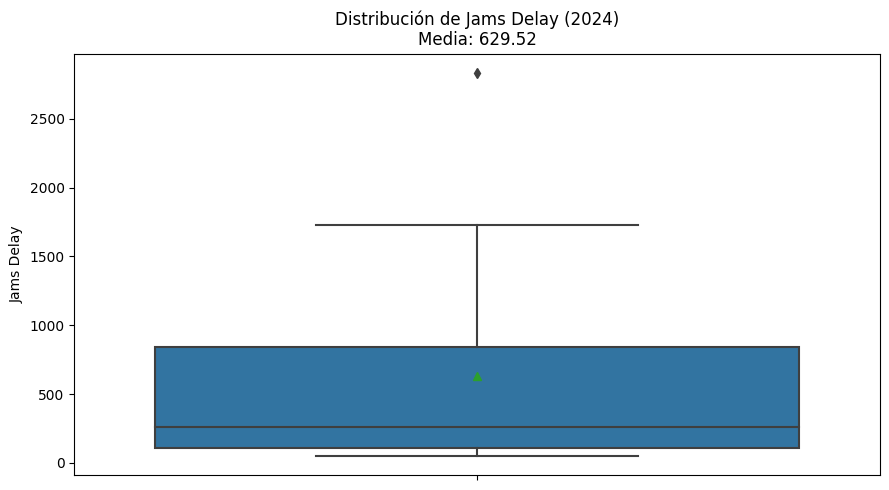

In [17]:
# Calcular el promedio de retrasos
mean_value = merged['jams_delay'].mean()

# Visualizar la distribución de retrasos
plt.figure(figsize=(9, 5))

sns.boxplot(
    y=merged['jams_delay'],
    showmeans=True
)

plt.title(f'Distribución de Jams Delay (2024)\nMedia: {mean_value:.2f}')
plt.ylabel('Jams Delay')
plt.tight_layout()
plt.show()


### 7.2 Distribución del PIB per cápita

Analizo la distribución de `city_gdp_capita` mediante un histograma para identificar cómo se distribuyen los valores del PIB per cápita entre las 15 ciudades estudiadas.

Incorporo una curva de densidad (KDE) como referencia visual para explorar la forma de la distribución y reconocer posibles concentraciones de valores.

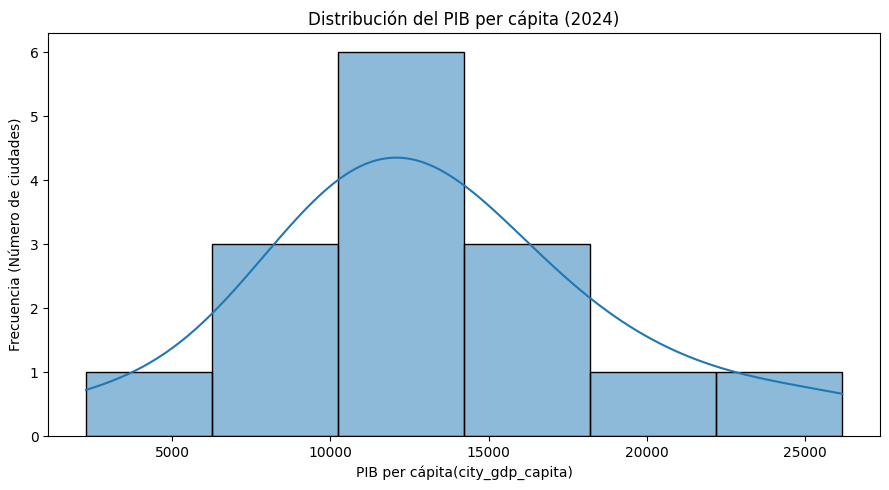

In [18]:
# Visualizar la distribución del PIB per cápita
plt.figure(figsize=(9, 5))

sns.histplot(
    data=merged,
    x='city_gdp_capita',
    kde=True
)

# Configurar títulos y etiquetas
plt.title('Distribución del PIB per cápita (2024)')
plt.xlabel('PIB per cápita(city_gdp_capita)')
plt.ylabel('Frecuencia (Número de ciudades)')

plt.tight_layout()
plt.show()


### 7.3 Relación entre el PIB per cápita y los retrasos por congestión

Utilizo un gráfico de dispersión para explorar la relación entre `city_gdp_capita` y `jams_delay` en las 15 ciudades analizadas.

Cada punto representa una ciudad, lo que permite identificar posibles tendencias, diferencias en el comportamiento de las variables y observaciones que se alejan del resto de la muestra.

In [ ]:
# Explorar la relación entre PIB per cápita y congestión
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=merged,
    x='city_gdp_capita',
    y='jams_delay',
    s=100
)

# Configurar títulos y etiquetas
plt.title('PIB per cápita y retrasos por congestión (2024)')
plt.xlabel('PIB per cápita')
plt.ylabel('Jams Delay')

plt.tight_layout()
plt.show()


In [ ]:
# Calcular la correlación de Pearson
correlacion = merged[
    ['city_gdp_capita', 'jams_delay']
].corr(method='pearson')

display(correlacion)

### 7.4 Hallazgos y conclusiones del análisis exploratorio

A partir de las visualizaciones y del análisis de correlación, identifico los siguientes hallazgos:

**1. Distribución de los retrasos por congestión**

El indicador `jams_delay` presenta una distribución asimétrica, con una media de 629.52. Ciudad de México destaca como un valor atípico, con un promedio de aproximadamente 2,833, superior al de las demás ciudades estudiadas.

**2. Diferencias económicas entre ciudades**

El histograma muestra una mayor concentración de valores del PIB per cápita aproximadamente entre 10,000 y 14,000, aunque existen diferencias considerables entre los extremos de la distribución.

**3. Relación entre movilidad y economía**

El gráfico de dispersión no muestra una tendencia lineal claramente definida entre el PIB per cápita y los retrasos por congestión.

El coeficiente de correlación de Pearson obtenido fue de **0.283**, lo que indica una asociación lineal positiva débil entre ambas variables.

Este resultado sugiere que, dentro de la muestra analizada, un mayor PIB per cápita no necesariamente se relaciona con un nivel considerablemente mayor de congestión.

**Conclusión**

El análisis identifica diferencias importantes en los indicadores económicos y las condiciones de movilidad de las 15 ciudades estudiadas durante 2024.

Aunque existe una correlación positiva débil entre el PIB per cápita y `jams_delay`, los resultados no permiten establecer una relación causal entre ambas variables.

Debido al tamaño de la muestra y a la presencia de valores extremos, interpreto estos hallazgos como exploratorios y reconozco que sería necesario ampliar el análisis para obtener conclusiones más sólidas y generalizables.


---

# 8. Exportación y documentación de resultados

En esta etapa preparo la entrega final del proyecto, exportando el conjunto de datos integrado y documentando los principales resultados del análisis.

El objetivo es conservar una versión estructurada y reutilizable de los datos, que facilite su consulta, reproducción y análisis posterior.

### 8.1 Exportación del dataset integrado

Exporto el DataFrame `merged` en formato CSV, conservando los indicadores de movilidad y economía de las 15 ciudades analizadas durante 2024.

Utilizo `index=False` para evitar que el índice de Pandas se incorpore como una columna adicional al archivo.


In [ ]:
# Exportar el conjunto de datos integrado
merged.to_csv(
    'ladb_mobility_economy_2024_clean.csv',
    index=False
)

# Verificar el archivo exportado
datos_exportados = pd.read_csv(
    'ladb_mobility_economy_2024_clean.csv'
)

print("Dimensiones:", datos_exportados.shape)
print("Valores nulos:", datos_exportados.isna().sum().sum())

display(datos_exportados.head())

**Resultado**

Exporté el conjunto de datos integrado en formato CSV, conservando los indicadores de movilidad y economía utilizados en el análisis.

Posteriormente, volví a importar el archivo para verificar su estructura y comprobar que conserva los 15 registros, las 14 columnas y la ausencia de valores nulos.

Este archivo constituye una versión preparada para su reutilización y permite continuar explorando las relaciones entre movilidad urbana e indicadores económicos.

# Resumen ejecutivo: Movilidad urbana y desempeño económico en Latinoamérica

### 1. Contexto y objetivo

Este proyecto analiza la relación entre las condiciones de movilidad urbana y los indicadores económicos de ciudades latinoamericanas durante 2024, tomando como referencia un escenario de evaluación de infraestructura de transporte para el Banco Interamericano de Desarrollo (BID).

Mi objetivo es identificar patrones de congestión vehicular y explorar su relación con el PIB per cápita, con el propósito de aportar información que pueda orientar investigaciones y decisiones sobre infraestructura urbana.

### 2. Cobertura de los datos

Utilicé información de TomTom Traffic Index y OECD Cities. Después de preparar, filtrar e integrar ambos conjuntos de datos, obtuve una muestra final de **15 ciudades latinoamericanas**, con 14 variables relacionadas con movilidad y economía.

El análisis corresponde al año 2024 y considera indicadores de congestión, tiempos de desplazamiento, PIB per cápita, desempleo, población y contaminación atmosférica.

### 3. Metodología aplicada

Desarrollé el análisis utilizando Python, Pandas, Matplotlib y Seaborn.

Primero realicé la exploración y limpieza de los datos, corrigiendo formatos numéricos, fechas y nombres de columnas. Posteriormente, calculé promedios anuales de movilidad por ciudad e integré los indicadores económicos mediante una unión interna (`inner join`).

Finalmente, utilicé diagramas de caja, histogramas y gráficos de dispersión para explorar las distribuciones y posibles relaciones. Complementé el análisis visual mediante el coeficiente de correlación de Pearson.

### 4. Principales hallazgos

Identifiqué diferencias importantes en las condiciones de movilidad y el desempeño económico de las ciudades estudiadas.

Ciudad de México presentó el valor promedio más elevado de `jams_delay`, aproximadamente 2,833, destacando como una observación atípica dentro de la muestra.

El análisis de correlación entre el PIB per cápita y `jams_delay` obtuvo un coeficiente de **0.283**, lo que indica una asociación lineal positiva débil.

Este resultado sugiere que un mayor PIB per cápita no necesariamente está acompañado de niveles considerablemente mayores de congestión vehicular.

### 5. Conclusiones y recomendaciones

Los resultados muestran que las condiciones de movilidad urbana varían considerablemente entre ciudades y que su relación con el PIB per cápita no sigue un patrón lineal fuerte dentro de la muestra estudiada.

Como siguiente etapa, recomiendo ampliar la cobertura de ciudades, evaluar otros indicadores de movilidad e incorporar variables como densidad poblacional, infraestructura de transporte y características urbanas.

También considero conveniente examinar por separado ciudades con valores elevados de congestión, para identificar qué factores podrían explicar sus condiciones de movilidad.

**En conclusión**, este análisis proporciona una primera aproximación cuantitativa a la relación entre movilidad y economía en ciudades latinoamericanas. Sus hallazgos tienen un carácter exploratorio y pueden servir como punto de partida para investigaciones más amplias y evaluaciones de infraestructura urbana.